# Лабораторная работа № 3. Кластеризация
**Дисциплина:** Языки прикладного программирования  
**Выполнил:** Манихин Алексей Владимирович  
**Группа:** СГН3-34Б

## Цель и постановка задачи
Разделить двумерную выборку S1 на 15 кластеров с помощью `KMeans`, `AgglomerativeClustering` и `DBSCAN`; построить графики с легендами, сравнить результаты и области применения методов.

Используется исходный `s1.txt` из предоставленного архива: **5000 строк, два числовых признака**. Исходный адрес, указанный в задании: http://cs.joensuu.fi/sipu/datasets/s1.txt. Интернет при выполнении ноутбука не требуется: точная копия данных встроена ниже.

**Как запустить:** открыть файл в Jupyter Notebook / JupyterLab, выбрать Python 3, выполнить **Restart Kernel and Run All Cells**. Результаты уже сохранены. Если библиотек нет, в терминале выполнить `python -m pip install jupyter numpy pandas matplotlib scikit-learn`, затем `python -m jupyter notebook`. Устанавливать пакеты заново при каждом запуске не нужно.

**Структура:** часть I — выполняемая лабораторная и выводы; часть II — теория; часть III — построчный разбор каждой программной ячейки; часть IV — вопросы к защите и связь с лекцией 4.

От исходного примера сохранены набор данных и три требуемых метода. Переработаны структура программы и графики, явно заданы параметры, добавлены проверки, анализ чувствительности DBSCAN, количественное сравнение и объяснения. Метки кластеров хранятся отдельно от признаков, чтобы случайно не подать результат одного алгоритма на вход другому.

Для KMeans и иерархического метода число 15 задаётся напрямую. У DBSCAN такого параметра нет: подбираются `eps` и `min_samples`, затем проверяется число полученных групп. Шум с меткой −1 в число кластеров не входит.

# Часть I. Выполнение работы
## 1. Импорт библиотек и настройки

In [1]:
import base64  # Стандартный модуль: превращает текст Base64 обратно в байты.
import zlib  # Стандартный модуль: распаковывает встроенную копию исходного файла.
from io import StringIO  # Позволяет читать строку так же, как открытый текстовый файл.
from time import perf_counter  # Даёт точные отметки времени для измерения длительности.

import numpy as np  # NumPy: двумерные массивы, маски, подсчёты и математические операции.
import pandas as pd  # Pandas: удобное представление таблиц результатов.
import matplotlib.pyplot as plt  # Pyplot: создание и отображение графиков.
import sklearn  # Нужен здесь для вывода версии установленного scikit-learn.
from IPython.display import display  # Показывает таблицы внутри Jupyter в читаемом виде.
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN  # Три требуемых метода.
from sklearn.metrics import silhouette_score  # Внутренняя оценка компактности и разделимости.

N_CLUSTERS = 15  # Требуемое число групп из условия лабораторной.
SEED = 42  # Фиксированное начальное состояние генератора случайных чисел.
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})  # Общий размер текста и чёткость графиков.
print("scikit-learn:", sklearn.__version__)  # Фиксируем версию для воспроизводимости результатов.

scikit-learn: 1.8.0


## 2. Загрузка и проверка данных
Следующая свёрнутая ячейка содержит только упакованные данные. Это не алгоритм кластеризации и не зашифрованный код. Упаковка нужна, чтобы передать один `.ipynb`, не заставляя пользователя искать отдельный `s1.txt`. При желании её можно заменить чтением `np.loadtxt("s1.txt")` из оригинального файла.

In [2]:
DATA_B64 = "..."  # Полная копия s1.txt, сжатая zlib и записанная в Base64.

In [3]:
raw_bytes = zlib.decompress(base64.b64decode(DATA_B64))  # Декодируем Base64 и распаковываем байты s1.txt.
X = np.loadtxt(StringIO(raw_bytes.decode("utf-8")))  # Читаем два столбца чисел; пробелы разделяют значения.
assert X.shape == (5000, 2), "Ожидается 5000 точек и 2 признака"  # Проверяем размер исходной выборки.
assert np.isfinite(X).all(), "В данных есть NaN или бесконечность"  # Все значения должны быть конечными.
print("Размер массива:", X.shape)  # Первая размерность — точки, вторая — признаки.
display(pd.DataFrame(X, columns=["X", "Y"]).describe().round(2))  # Показываем статистику обоих признаков.

Размер массива: (5000, 2)


,X,Y
count,5000.00,5000.00
mean,514937.56,494709.29
std,244465.90,235840.85
min,19835.00,51121.00
25%,320352.50,320107.75
50%,505338.50,526259.50
75%,786228.75,713713.50
max,961951.00,970756.00


Каждая строка `X[i]` — один объект $(x_i,y_i)$. Столбцы имеют сопоставимые диапазоны и описывают координаты одной плоскости; в этой работе сохраняем исходную геометрию и единицы измерения. Это осознанный выбор, а не универсальный отказ от масштабирования. Если один признак измеряет рубли, а другой годы, большие численные значения могут подавить малые; тогда требуется обоснованное масштабирование. После масштабирования `eps` пришлось бы подбирать заново.

## 3. Общая функция визуализации
Один и тот же код используется для исходных данных и всех результатов. Шум отображается серыми крестиками. Цвет и номер кластера имеют смысл **внутри конкретного графика**: совпадение номера в разных алгоритмах не означает совпадение групп.

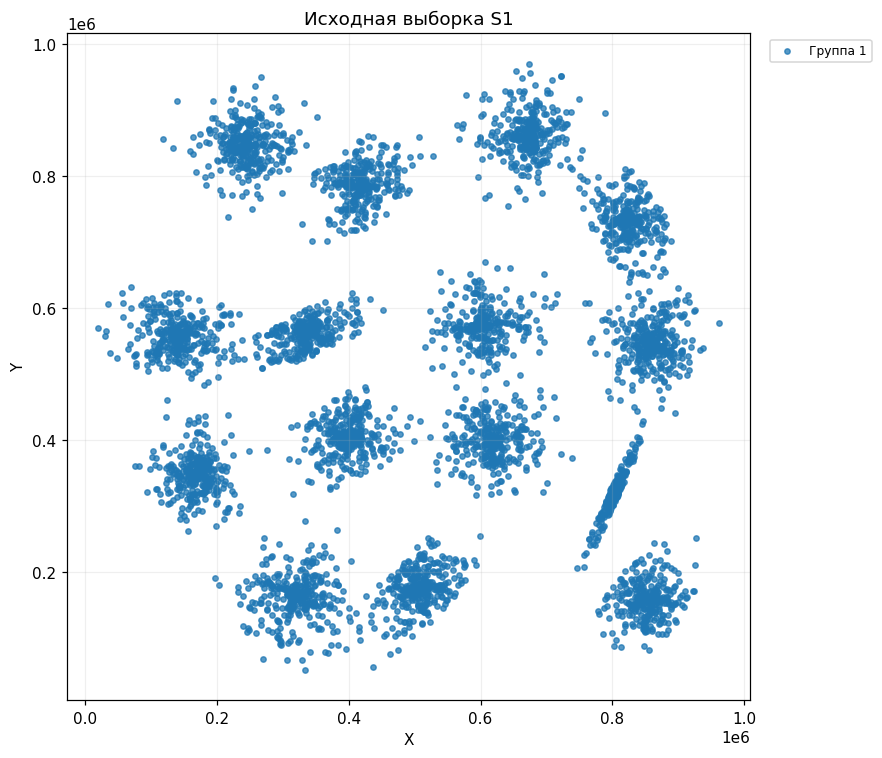

In [4]:
def plot_clusters(points, labels, title, centers=None):  # Принимаем координаты, метки, заголовок и необязательные центры.
    fig, ax = plt.subplots(figsize=(10, 7))  # Создаём отдельную фигуру и оси для одного результата.
    unique_labels = np.unique(labels)  # Получаем отсортированные метки без повторений.
    palette = plt.get_cmap("tab20")  # Берём дискретную палитру из 20 цветов: для 15 групп достаточно.
    for position, label in enumerate(unique_labels):  # Перебираем номер цвета и соответствующую метку.
        mask = labels == label  # Булева маска выбирает точки только текущей группы.
        if label == -1:  # В scikit-learn DBSCAN обозначает шум числом минус один.
            ax.scatter(points[mask, 0], points[mask, 1], c="gray", marker="x", s=20, label="Шум (−1)")  # Рисуем шум отдельно.
        else:  # Все остальные метки обозначают обычные кластеры.
            ax.scatter(points[mask, 0], points[mask, 1], color=palette(position % 20), s=12, alpha=0.75, label=f"Группа {label + 1}")  # Рисуем выбранные точки.
    if centers is not None:  # Центры рисуем только тогда, когда они переданы явно.
        ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=100, label="Центроиды", zorder=3)  # Чёрные X поверх точек.
    ax.set(title=title, xlabel="X", ylabel="Y")  # Подписываем название графика и обе координатные оси.
    ax.set_aspect("equal", adjustable="box")  # Одинаковая единица длины по X и Y сохраняет форму групп.
    ax.grid(alpha=0.2)  # Слабая сетка помогает читать координаты и не закрывает точки.
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)  # Легенду размещаем справа от области данных.
    fig.tight_layout()  # Подбираем отступы, чтобы подписи и легенда помещались на фигуре.
    plt.show()  # Отображаем готовую фигуру в выводе текущей ячейки Jupyter.

plot_clusters(X, np.zeros(len(X), dtype=int), "Исходная выборка S1")  # Нули нужны лишь для одного общего цвета, это не кластеризация.

## 4. KMeans: 15 кластеров
Задаём `k-means++` для более удачного расположения начальных центров. `n_init=10` запускает алгоритм с десятью инициализациями; сохраняется результат с наименьшей суммой квадратов расстояний. `random_state=42` делает случайные шаги воспроизводимыми в той же программной среде.

Сумма квадратов расстояний: 8917615616867.26
Число итераций лучшего запуска: 5


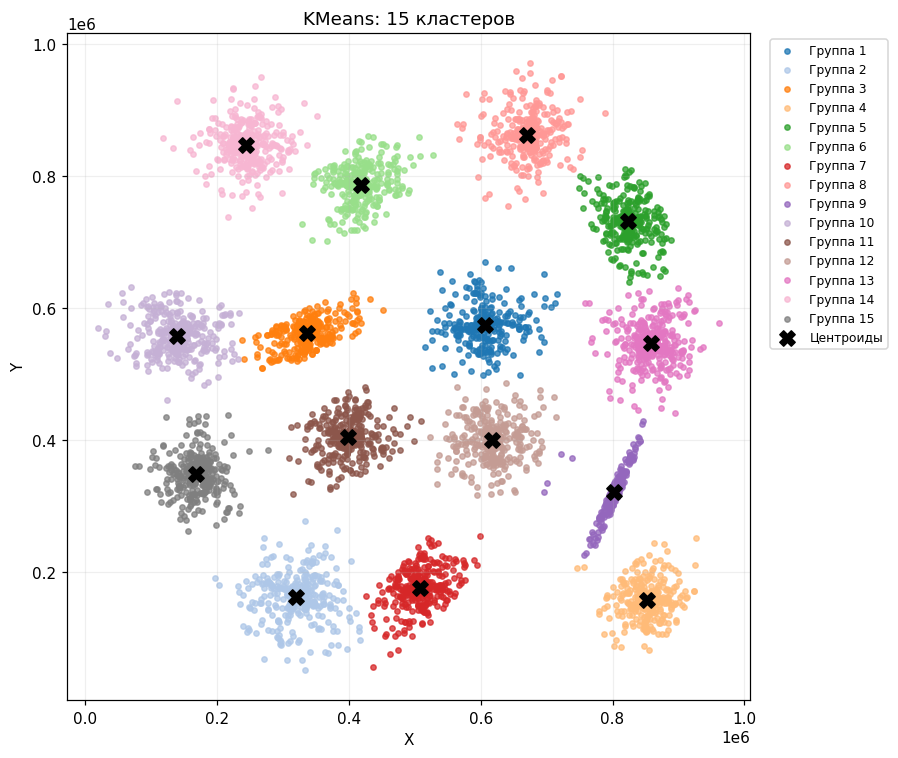

In [5]:
kmeans = KMeans(n_clusters=N_CLUSTERS, init="k-means++", n_init=10, random_state=SEED)  # Создаём модель с явными параметрами.
start = perf_counter()  # Запоминаем время непосредственно перед обучением.
kmeans_labels = kmeans.fit_predict(X)  # Обучаем модель и получаем по одной метке на каждую точку.
kmeans_seconds = perf_counter() - start  # Вычисляем длительность обучения и назначения меток.
plot_clusters(X, kmeans_labels, "KMeans: 15 кластеров", centers=kmeans.cluster_centers_)  # Показываем группы и найденные центры.
print(f"Сумма квадратов расстояний: {kmeans.inertia_:.2f}")  # Inertia — критерий, который минимизирует KMeans.
print("Число итераций лучшего запуска:", kmeans.n_iter_)  # Это число шагов, а не количество запусков n_init.

## 5. Агломеративная кластеризация: 15 кластеров
Используем `linkage="ward"`. На каждом шаге объединяется пара кластеров с наименьшим приростом суммарного внутрикластерного квадратичного разброса. Это точнее, чем фраза «объединяем два ближайших центра»: критерий Ward учитывает ещё и размеры групп. По умолчанию используется евклидова геометрия.

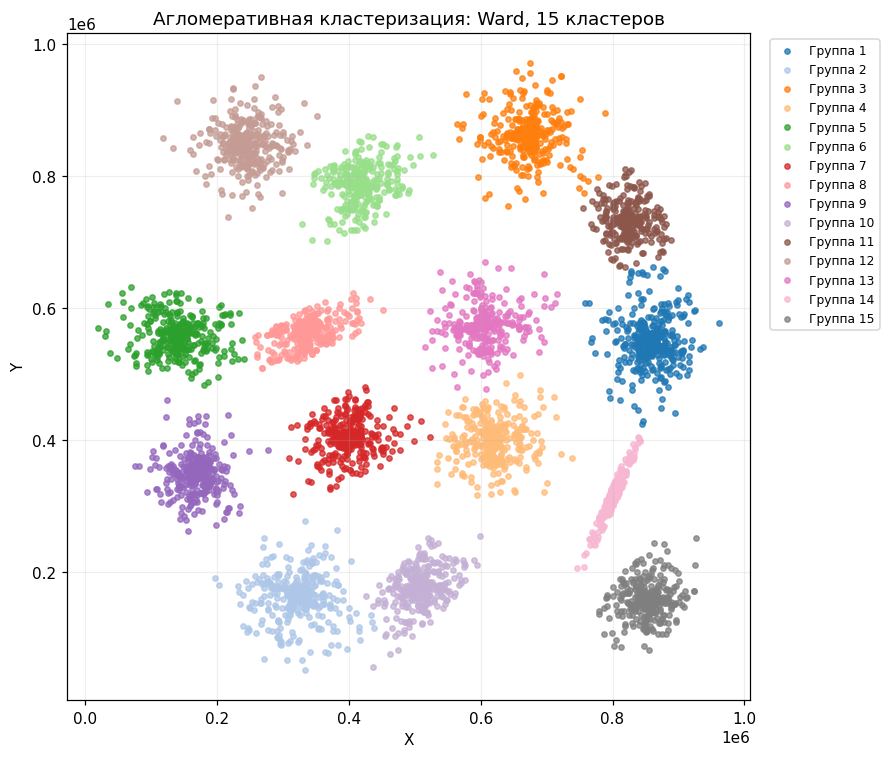

In [6]:
hierarchical = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward")  # Выбираем 15 групп и правило объединения Ward.
start = perf_counter()  # Начальная отметка времени для второго метода.
hierarchical_labels = hierarchical.fit_predict(X)  # Строим иерархию слияний и получаем разбиение на 15 групп.
hierarchical_seconds = perf_counter() - start  # Время этого запуска без отрисовки и вычисления силуэта.
plot_clusters(X, hierarchical_labels, "Агломеративная кластеризация: Ward, 15 кластеров")  # Отображаем результат без центроидов.

## 6. DBSCAN: исследование радиуса соседства
При фиксированном `min_samples=5` проверяем несколько радиусов в исходных единицах координат. В числе соседей учитывается сама точка. Выбор `20500` ниже обоснован этой таблицей и требованием получить 15 групп; это не универсально лучший радиус для любых данных.

In [7]:
eps_values = [15000, 18000, 20000, 20500, 22000, 25000, 30000]  # Кандидаты радиуса вокруг значения из исходного примера.
eps_rows = []  # Список для строк будущей таблицы эксперимента.
for eps in eps_values:  # Повторяем обучение для каждого радиуса из списка.
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X)  # Метки текущего запуска; признаки X остаются прежними.
    cluster_count = len(set(labels) - {-1})  # Убираем метку шума из множества и считаем оставшиеся группы.
    noise_count = int(np.sum(labels == -1))  # Считаем точки, которые алгоритм признал шумом.
    eps_rows.append({"eps": eps, "Кластеры": cluster_count, "Шум, точек": noise_count})  # Запоминаем один результат эксперимента.
eps_table = pd.DataFrame(eps_rows)  # Превращаем список словарей в таблицу.
display(eps_table)  # Отображаем все радиусы, числа групп и число шумовых точек.

,eps,Кластеры,"Шум, точек"
0,15000,23,333
1,18000,21,193
2,20000,17,152
3,20500,15,140
4,22000,12,110
5,25000,11,66
6,30000,8,37


Основных точек: 4740
Шумовых точек: 140


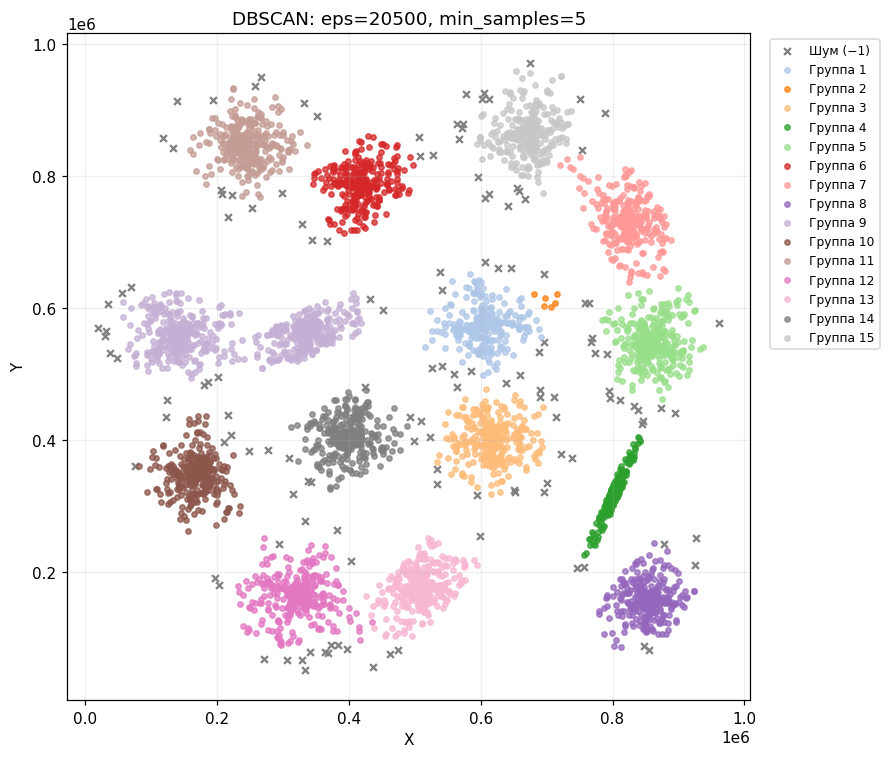

,Число точек
Метка,
-1,140
0,278
1,6
2,323
3,310
4,335
5,308
6,324
7,320


In [8]:
dbscan = DBSCAN(eps=20500, min_samples=5)  # Выбранные по эксперименту параметры для исходного масштаба S1.
start = perf_counter()  # Начинаем отдельное измерение итогового запуска DBSCAN.
dbscan_labels = dbscan.fit_predict(X)  # Находим плотностные группы и шумовые точки.
dbscan_seconds = perf_counter() - start  # Измеряем время без предварительного перебора eps.
plot_clusters(X, dbscan_labels, "DBSCAN: eps=20500, min_samples=5")  # Цветные кластеры и серые крестики шума.
print("Основных точек:", len(dbscan.core_sample_indices_))  # Индексы core-точек хранятся в обученной модели.
print("Шумовых точек:", int(np.sum(dbscan_labels == -1)))  # Отдельно показываем размер шума.
dbscan_sizes = pd.Series(dbscan_labels, name="Метка").value_counts().sort_index()  # Подсчитываем объекты для каждой метки, включая шум −1.
display(dbscan_sizes.rename("Число точек").to_frame())  # Проверяем размеры групп, чтобы заметить слияние и маленькие группы.

## 7. Количественное сравнение
Для точки $i$ силуэт равен $s(i)=(b(i)-a(i))/\max(a(i),b(i))$, где $a(i)$ — среднее расстояние до остальных точек своей группы, $b(i)$ — минимальное среднее расстояние до точек другой группы. Средний силуэт лежит в диапазоне от −1 до 1. Чем он выше, тем в среднем компактнее и лучше разделены группы в выбранной метрике. Это **не доля правильных ответов**.

У всех методов оцениваем **одни и те же 1500 точек**, случайно выбранных из точек, не признанных шумом DBSCAN. Это делает оценки по набору объектов сопоставимыми, но исключает сложные шумовые точки из оценки всех методов. Поэтому обязательно отдельно сообщаем покрытие и число шума. Силуэт считается на этой подвыборке; это приближённая оценка, не полный силуэт всех 5000 точек. Истинных меток в исходном файле нет, поэтому accuracy не вычисляем.

Время — один запуск в текущей среде. Измеряется только `fit_predict`; для DBSCAN не включён поиск параметров. Эти значения не являются надёжным сравнительным бенчмарком.

In [9]:
common_indices = np.flatnonzero(dbscan_labels != -1)  # Индексы общей области оценки: все нешумовые точки DBSCAN.
rng = np.random.default_rng(SEED)  # Создаём отдельный воспроизводимый генератор для выбора подвыборки.
sample_indices = rng.choice(common_indices, size=min(1500, len(common_indices)), replace=False)  # Берём разные точки без повторов.
results = [("KMeans", kmeans_labels, kmeans_seconds), ("Ward", hierarchical_labels, hierarchical_seconds), ("DBSCAN", dbscan_labels, dbscan_seconds)]  # Храним название, метки и время каждого метода.
summary_rows = []  # Здесь будут строки итоговой таблицы.
for name, labels, seconds in results:  # Распаковываем по три значения для каждого алгоритма.
    cluster_count = len(set(labels) - {-1})  # Число найденных групп без учёта шума.
    noise_count = int(np.sum(labels == -1))  # Число объектов, которым не назначен обычный кластер.
    score = silhouette_score(X[sample_indices], labels[sample_indices])  # Оцениваем все методы на одинаковых точках.
    summary_rows.append({"Метод": name, "Кластеры": cluster_count, "Шум": noise_count, "Покрытие, %": 100 * (len(X) - noise_count) / len(X), "Силуэт": score, "Время, с": seconds})  # Одна строка сравнения.
    assert len(labels) == len(X), "Для каждой точки должна быть метка"  # Проверяем число результатов.
    assert cluster_count == N_CLUSTERS, "Не получены требуемые 15 кластеров"  # Проверяем условие задания для каждого метода.
summary = pd.DataFrame(summary_rows)  # Собираем строки в DataFrame.
display(summary.round({"Покрытие, %": 1, "Силуэт": 4, "Время, с": 4}))  # Округляем только отображение, исходные числа остаются точными.
print("Проверки пройдены: каждый метод выделил 15 кластеров.")  # Сообщение появляется после успешных проверок.

Проверки пройдены: каждый метод выделил 15 кластеров.


,Метод,Кластеры,Шум,"Покрытие, %",Силуэт,"Время, с"
0,KMeans,15,0,100.0,0.7329,0.0452
1,Ward,15,0,100.0,0.7304,0.3658
2,DBSCAN,15,140,97.2,0.6802,0.0172


## 8. Выводы
1. Все три метода выделяют **15 кластеров** на исходной выборке при выбранных параметрах. KMeans и Ward распределяют все 5000 точек. DBSCAN относит к кластерам 4860 точек (**97,2%**), а 140 точек (**2,8%**) считает шумом.
2. На графиках видны преимущественно компактные, хорошо разделённые скопления. Для такой геометрии KMeans — естественный выбор: его критерий напрямую поощряет компактность вокруг среднего. Ward также даёт близкое по геометрии разбиение.
3. DBSCAN полезен, если важно выделить разреженные точки отдельно. Но найденный шум — результат заданного порога плотности, а не доказанные ошибки измерения. Само совпадение количества групп с числом 15 не доказывает истинность разбиения. **В нашем результате DBSCAN слил два соседних скопления слева около Y=560000 в группу из 660 точек (метка 8, на графике «Группа 9») и выделил маленькую группу из 6 точек около (701801, 611644) (метка 1, «Группа 2»).** Поэтому формальное выполнение требования о 15 группах не означает восстановления тех же геометрических скоплений, что у KMeans и Ward.
4. При `eps=15000` получаются 23 группы и 333 шумовые точки; при `eps=20500` — 15 и 140; при `eps=30000` — 8 и 37. Радиус существенно меняет результат. Слишком маленький радиус дробит плотные области и увеличивает шум, слишком большой соединяет соседние области. Число кластеров вообще не обязано монотонно убывать при каждом увеличении eps: отдельные точки сначала могут образовывать новые группы, а затем группы сливаются.
5. На общей подвыборке силуэт составил примерно **0,7329 у KMeans, 0,7304 у Ward и 0,6802 у DBSCAN**. По этому критерию KMeans и Ward близки, DBSCAN хуже разделяет компактные скопления при выбранных параметрах. Величина силуэта помогает сравнить геометрию разбиений, но не заменяет предметную оценку. Здесь сравнение ограничено общей подвыборкой нешумовых точек и одним набором данных.
6. Для вытянутых и изогнутых плотных групп чаще подходит DBSCAN; KMeans и Ward склонны делить пространство на компактные области. При резко разной плотности единый `eps` у DBSCAN становится проблемой. Иерархический подход полезен для изучения вложенности групп, но обычно требует больше ресурсов на больших выборках.

Работа соблюдает DRY: отрисовка вынесена в одну функцию. Основные этапы оставлены последовательными и явно видимыми, что соответствует KISS. Дополнительные классы, универсальный фреймворк и сложный интерфейс не вводятся, что соответствует YAGNI.

# Часть II. Теория по лекции 3 и заданию

## 1. Что именно мы ищем
Кластеризация — обучение без учителя: на входе есть признаки объектов, но нет правильного класса каждого объекта. Ищем разбиение, при котором объекты внутри группы похожи, а разные группы отличаются. «Похожи» здесь означает близки в евклидовом пространстве:
$$d(p,q)=\sqrt{(p_x-q_x)^2+(p_y-q_y)^2}.$$
Для $(1,2)$ и $(4,6)$ расстояние равно $\sqrt{9+16}=5$.

Число 15 в условии — требование к количеству групп, а не обучающие ответы. Алгоритм всё равно сам решает, какая точка к какой группе относится. Номер кластера — условное имя: замена номеров 0 и 7 не меняет разбиение. Нельзя оценивать согласие двух кластеризаций простым сравнением равенства чисел меток.

**Классификация** учится по примерам с известными классами и предсказывает категорию нового объекта. **Регрессия** предсказывает число. Например, разбить клиентов по похожести — кластеризация, определить мошенническую операцию по размеченным примерам — классификация, предсказать стоимость квартиры — регрессия. В лекции 3 это разделы на слайдах 14–29.

## 2. KMeans подробно — лекция 3, слайды 15–17
Пусть $C_1,\ldots,C_k$ — группы, а $\mu_j$ — их центры. Минимизируем:
$$J=\sum_{j=1}^{k}\sum_{x_i\in C_j}\|x_i-\mu_j\|^2.$$
Это `inertia_` в scikit-learn. Квадрат сильнее штрафует далёкие точки; поэтому выброс может заметно сдвинуть центр.

**Шаг 1. Инициализация.** Выбираем k начальных центров. В нашем коде `k-means++`: первый центр выбирается случайно, следующие выбираются с предпочтением точек, далёких от уже выбранных центров. Это улучшает старт, но не гарантирует глобальный минимум.

**Шаг 2. Назначение.** Для каждой точки считаем расстояния до всех центров и выбираем ближайший. При обычной евклидовой метрике можно сравнивать квадраты расстояний: корень не меняет порядок.

**Шаг 3. Пересчёт.** Новый центр группы — среднее всех её точек:
$$\mu_j=\frac{1}{|C_j|}\sum_{x_i\in C_j}x_i.$$
Среднее считается отдельно по каждой координате. Для $(1,1),(2,1),(3,4)$ центр равен $(2,2)$; он не обязан совпадать с какой-либо исходной точкой.

**Шаг 4. Повторение.** Снова назначаем точки ближайшим центрам, затем пересчитываем центры. Теоретически идеальные шаги не увеличивают J. Реализация останавливается при сходимости с учётом допуска или ограничения итераций; не нужно ждать абсолютно точного равенства вещественных чисел. Строгая неизменность меток тоже означает сходимость.

**Числовой пример в 1D.** Данные $1,2,8,9$, $k=2$, стартовые центры 1 и 8. После назначения группы $(1,2)$ и $(8,9)$. Новые центры 1,5 и 8,5. Повторное назначение ничего не меняет. Сумма квадратов отклонений равна $0,25+0,25+0,25+0,25=1$.

**Почему именно среднее?** Для одной координаты минимизируем $\sum_i(x_i-\mu)^2$. Производная по $\mu$ равна $2\sum_i(\mu-x_i)$. Приравниваем к нулю: $n\mu=\sum_i x_i$. Если минимизировать сумму модулей отклонений, оптимальным будет уже медиана.

**Локальный минимум.** Из другого старта можно получить другое разбиение. Поэтому делаем 10 инициализаций и выбираем лучшую по J. `n_init=10` — десять полных запусков, а `n_iter_` — количество итераций в лучшем из них. `random_state` фиксирует случайность, но не «улучшает точность» сам по себе.

**Когда хорош:** компактные группы с сопоставимыми масштабами и известным k. **Слабости:** заранее нужен k; чувствительность к выбросам и масштабу; плохое описание колец, дуг и групп сильно разной плотности. Каждой точке назначается группа, отдельного понятия шума нет. При росте k оптимально достижимая инерция не растёт, поэтому выбирать k просто по минимуму инерции нельзя: крайний вариант — отдельный центр для каждой точки.

**Сложность:** ориентировочно $O(r\,t\,n\,k\,d)$, где r — число инициализаций, t — итерации, n — точки, k — центры, d — признаки. Запись O(n) в методичке предполагает, что прочие множители фиксированы.

## 3. Иерархическая кластеризация — лекция 3, слайды 18–19
Иерархическая кластеризация бывает агломеративной (слияние снизу вверх) и дивизивной (разделение сверху вниз). В работе используется первый вариант.

1. Изначально каждая точка — отдельная группа: всего 5000 групп.
2. Вычисляем, какую пару выгоднее объединить по выбранному правилу связи (`linkage`).
3. Объединяем эту пару, пересчитываем необходимую информацию и повторяем.
4. Для результата берём уровень дерева с 15 группами. Конкретная реализация может построить полное дерево, даже если нужны только эти 15 групп.

**Правила связи:** single — минимальное расстояние между точками двух групп; complete — максимальное; average — среднее попарное расстояние; centroid — расстояние между центрами масс. Последнее описывает семейство иерархических методов, но не является допустимым `linkage` у используемого класса `AgglomerativeClustering`. Ward — отдельное правило: минимальный прирост суммы квадратов отклонений внутри групп.

Для Ward цена слияния A и B:
$$\Delta(A,B)=\frac{|A|\,|B|}{|A|+|B|}\|\mu_A-\mu_B\|^2.$$
Размеры групп важны. Для двух одиночных точек на расстоянии 2 прирост равен $(1\cdot1/2)\cdot 4=2$. Для двух групп по 10 точек с тем же расстоянием центров прирост равен $(10\cdot10/20)\cdot4=20$. Поэтому «ближайшие центры» не полностью описывают Ward.

**Дендрограмма** — дерево объединений. Листья соответствуют исходным объектам, развилки — слияниям. Высота отражает величину критерия связи в принятом представлении; не всегда это буквально расстояние между центрами. Горизонтальный разрез задаёт разбиение: число пересечённых ветвей соответствует числу групп. В работе дендрограмма не требуется, поэтому не строится перегруженное дерево из 5000 листьев.

**Плюсы:** можно изучать вложенность; нет случайного выбора начальных центров; можно выбрать подходящее правило связи. **Минусы:** решение о слиянии необратимо; ресурсоёмкость на больших наборах; чувствительность к масштабу и выбросам зависит от linkage. Single может соединять группы через цепочки точек. Ward, как и KMeans, предпочитает компактные группы. Иерархическая кластеризация не «всегда устойчивее к шуму».

Для типичных реализаций без специальных ограничений часто требуется квадратичная память и примерно квадратичное время, но точная сложность зависит от метода и реализации. На одинаковом входе, при одинаковых параметрах и порядке строк результат воспроизводим; при равных расстояниях способ разрешения ничьей может зависеть от порядка данных.

## 4. DBSCAN — лекция 3, слайды 20–21
DBSCAN группирует точки по плотностной связности. Вводится eps-окрестность:
$$N_\varepsilon(p)=\{q:d(p,q)\leq\varepsilon\}.$$
`eps` — радиус этой окрестности, `min_samples` — минимальное число точек в ней для признания p основной точкой. В scikit-learn **сама p включается в подсчёт**. При `min_samples=5` достаточно самой точки и ещё четырёх соседей.

Три типа точек:

* **Основная / core:** в её окрестности не меньше `min_samples` точек.
* **Граничная / border:** собственной плотности недостаточно, но она находится в eps-окрестности основной точки. Принадлежит кластеру, однако сама не продолжает расширение области.
* **Шум / noise:** не основная и не граничная; получает метку −1. Если на промежуточном этапе точку пометили шумом, позднее она может попасть в кластер как граничная.

**Ход алгоритма.** Берём ещё не обработанную точку, находим соседей. Если она основная, создаём новую группу и расширяем её через основные точки соседних окрестностей. Граничные точки присоединяем, но через них расширение не продолжаем. Повторяем для остальных областей. Изолированные неосновные точки остаются шумом. Случайные начальные центры не нужны.

**Почему диаметр может быть больше eps?** Пусть основные точки A, B, C образуют цепочку: A близко к B, B близко к C, но A далеко от C. Через B все они могут оказаться в одной группе. Поэтому `eps=20500` не требует, чтобы любые две точки группы находились не дальше 20500. Через длинную цепочку основных точек строится большая и изогнутая область.

**Не путать:** `min_samples=5` — условие плотности окрестности основной точки, не команда «создать группы по пять объектов» и не желаемое количество групп. `eps` — расстояние, `min_samples` — число точек: единицы измерения разные.

**Параметры.** Малый eps обычно даёт много шума и дробление, слишком большой объединяет разные области. Увеличение min_samples делает критерий основной точки более строгим. Для поиска eps полезны график расстояния до k-го соседа, сведения о масштабе данных, просмотр результата и проверка устойчивости. В этой работе выполнен прозрачный перебор нескольких значений с фиксированным min_samples.

**Плюсы:** число групп заранее не нужно; есть шум; можно находить невыпуклые группы. **Минусы:** нужен разумный eps; единый порог плохо подходит к резко разным плотностям; в высокой размерности расстояния могут хуже отражать близость; плотные мостики могут объединять визуально разные группы. При неоднозначной граничной точке, соседствующей с основными точками разных групп, принадлежность может зависеть от порядка обхода. Это не случайная инициализация.

**Сложность:** с эффективным пространственным индексом и благоприятными данными поиск часто близок к $O(n\log n)$, но в худшем случае может быть $O(n^2)$. Реализация scikit-learn при больших окрестностях может потребовать квадратичную память. Нельзя обещать, что DBSCAN всегда быстрее KMeans.

## 5. Сравнение в одной таблице
| Свойство | KMeans | Agglomerative, Ward | DBSCAN |
|---|---|---|---|
| Что задаём | k | k и linkage | eps и min_samples |
| Главная идея | Ближайший центр и пересчёт среднего | Последовательное слияние | Связность плотных окрестностей |
| Что оптимизируем | Сумму квадратов расстояний до центров | На каждом шаге прирост внутригруппового разброса | Не ту же целевую функцию; ищем плотностные компоненты |
| Шум | Нет отдельной метки | Нет отдельной метки | Метка −1 |
| Типичная удобная форма | Компактная | Компактная при Ward | Произвольная при достаточной плотности |
| Случайный старт | Да | Нет | Нет |
| Предсказание для новой точки | Есть predict | Нет обычного predict у этого класса | Нет обычного predict у этого класса |

## 6. Почему наш код безопасно разделяет признаки и результаты
`X` всегда имеет форму `(5000, 2)`. Массив меток каждого метода имеет форму `(5000,)`. `fit_predict(X)` возвращает метки, но не дописывает третий столбец к X. Если добавить метки KMeans в таблицу и потом передать все столбцы DBSCAN, алгоритм начнёт учитывать выдуманный третий признак — номер группы. Расстояния изменятся без содержательного основания. Отдельные переменные предотвращают эту ошибку.

В выражении `X[mask, 0]` mask выбирает строки, а 0 — первый столбец. `X[:, 1]` берёт второй столбец для всех строк. `labels == -1` сравнивает каждый элемент и создаёт булев массив. Для NumPy True при суммировании даёт 1, False — 0, поэтому `np.sum(labels == -1)` считает шумовые точки.

## 7. Силуэт и границы выводов
Если точка находится близко к своей группе и далеко от соседних, a мало, b велико, силуэт близок к 1. Если a и b похожи, значение близко к 0. Если точке в среднем ближе чужая группа, a больше b и силуэт отрицателен. Например, a=2 и b=8 дают $(8-2)/8=0,75$.

В нашем сравнении силуэт вычислен только на общей подвыборке. Это осознанный компромисс времени и сопоставимости. Он не оценивает, насколько правильно DBSCAN исключил шум, поэтому рядом показано покрытие. Сам по себе более высокий силуэт у метода, исключившего сложные точки, не доказывает его превосходства.

Метрика применима, когда число различных меток от 2 до n−1. Для одиночной точки в кластере scikit-learn использует силуэт 0. При произвольном изменении параметров могут появиться все шумовые точки или одна группа; тогда данный учебный код сравнения нужно дополнить обработкой таких случаев. Для проверенных параметров эти случаи не возникают.

# Часть III. Построчный разбор кода
Ниже каждая непустая программная строка повторена и объяснена отдельно. Номера локальны для соответствующей ячейки. Пустые строки только разделяют блоки и не выполняют действий. Отступы внутри функций, циклов и условий определяют, к какому блоку принадлежит команда.

**Ячейка встроенных данных:** `DATA_B64 = "..."` присваивает переменной длинную строку. Все символы внутри кавычек — данные исходного файла после сжатия и Base64, а не инструкции Python. Одна и та же строка при распаковке восстанавливает исходный файл байт в байт. Эта техническая упаковка не влияет на кластеризацию.

## 1. Импорты

**Строка 1.**
```python
import base64
```
Стандартный модуль: превращает текст Base64 обратно в байты.

**Строка 2.**
```python
import zlib
```
Стандартный модуль: распаковывает встроенную копию исходного файла.

**Строка 3.**
```python
from io import StringIO
```
Позволяет читать строку так же, как открытый текстовый файл.

**Строка 4.**
```python
from time import perf_counter
```
Даёт точные отметки времени для измерения длительности.

**Строка 6.**
```python
import numpy as np
```
NumPy: двумерные массивы, маски, подсчёты и математические операции.

**Строка 7.**
```python
import pandas as pd
```
Pandas: удобное представление таблиц результатов.

**Строка 8.**
```python
import matplotlib.pyplot as plt
```
Pyplot: создание и отображение графиков.

**Строка 9.**
```python
import sklearn
```
Нужен здесь для вывода версии установленного scikit-learn.

**Строка 10.**
```python
from IPython.display import display
```
Показывает таблицы внутри Jupyter в читаемом виде.

**Строка 11.**
```python
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
```
Три требуемых метода.

**Строка 12.**
```python
from sklearn.metrics import silhouette_score
```
Внутренняя оценка компактности и разделимости.

**Строка 14.**
```python
N_CLUSTERS = 15
```
Требуемое число групп из условия лабораторной.

**Строка 15.**
```python
SEED = 42
```
Фиксированное начальное состояние генератора случайных чисел.

**Строка 16.**
```python
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
```
Общий размер текста и чёткость графиков.

**Строка 17.**
```python
print("scikit-learn:", sklearn.__version__)
```
Фиксируем версию для воспроизводимости результатов.

## 2. Чтение данных

**Строка 1.**
```python
raw_bytes = zlib.decompress(base64.b64decode(DATA_B64))
```
Декодируем Base64 и распаковываем байты s1.txt.

**Строка 2.**
```python
X = np.loadtxt(StringIO(raw_bytes.decode("utf-8")))
```
Читаем два столбца чисел; пробелы разделяют значения.

**Строка 3.**
```python
assert X.shape == (5000, 2), "Ожидается 5000 точек и 2 признака"
```
Проверяем размер исходной выборки.

**Строка 4.**
```python
assert np.isfinite(X).all(), "В данных есть NaN или бесконечность"
```
Все значения должны быть конечными.

**Строка 5.**
```python
print("Размер массива:", X.shape)
```
Первая размерность — точки, вторая — признаки.

**Строка 6.**
```python
display(pd.DataFrame(X, columns=["X", "Y"]).describe().round(2))
```
Показываем статистику обоих признаков.

## 3. Построение графика

**Строка 1.**
```python
def plot_clusters(points, labels, title, centers=None):
```
Принимаем координаты, метки, заголовок и необязательные центры.

**Строка 2.**
```python
fig, ax = plt.subplots(figsize=(10, 7))
```
Создаём отдельную фигуру и оси для одного результата.

**Строка 3.**
```python
unique_labels = np.unique(labels)
```
Получаем отсортированные метки без повторений.

**Строка 4.**
```python
palette = plt.get_cmap("tab20")
```
Берём дискретную палитру из 20 цветов: для 15 групп достаточно.

**Строка 5.**
```python
for position, label in enumerate(unique_labels):
```
Перебираем номер цвета и соответствующую метку.

**Строка 6.**
```python
mask = labels == label
```
Булева маска выбирает точки только текущей группы.

**Строка 7.**
```python
if label == -1:
```
В scikit-learn DBSCAN обозначает шум числом минус один.

**Строка 8.**
```python
ax.scatter(points[mask, 0], points[mask, 1], c="gray", marker="x", s=20, label="Шум (−1)")
```
Рисуем шум отдельно.

**Строка 9.**
```python
else:
```
Все остальные метки обозначают обычные кластеры.

**Строка 10.**
```python
ax.scatter(points[mask, 0], points[mask, 1], color=palette(position % 20), s=12, alpha=0.75, label=f"Группа {label + 1}")
```
Рисуем выбранные точки.

**Строка 11.**
```python
if centers is not None:
```
Центры рисуем только тогда, когда они переданы явно.

**Строка 12.**
```python
ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=100, label="Центроиды", zorder=3)
```
Чёрные X поверх точек.

**Строка 13.**
```python
ax.set(title=title, xlabel="X", ylabel="Y")
```
Подписываем название графика и обе координатные оси.

**Строка 14.**
```python
ax.set_aspect("equal", adjustable="box")
```
Одинаковая единица длины по X и Y сохраняет форму групп.

**Строка 15.**
```python
ax.grid(alpha=0.2)
```
Слабая сетка помогает читать координаты и не закрывает точки.

**Строка 16.**
```python
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
```
Легенду размещаем справа от области данных.

**Строка 17.**
```python
fig.tight_layout()
```
Подбираем отступы, чтобы подписи и легенда помещались на фигуре.

**Строка 18.**
```python
plt.show()
```
Отображаем готовую фигуру в выводе текущей ячейки Jupyter.

**Строка 20.**
```python
plot_clusters(X, np.zeros(len(X), dtype=int), "Исходная выборка S1")
```
Нули нужны лишь для одного общего цвета, это не кластеризация.

## 4. KMeans

**Строка 1.**
```python
kmeans = KMeans(n_clusters=N_CLUSTERS, init="k-means++", n_init=10, random_state=SEED)
```
Создаём модель с явными параметрами.

**Строка 2.**
```python
start = perf_counter()
```
Запоминаем время непосредственно перед обучением.

**Строка 3.**
```python
kmeans_labels = kmeans.fit_predict(X)
```
Обучаем модель и получаем по одной метке на каждую точку.

**Строка 4.**
```python
kmeans_seconds = perf_counter() - start
```
Вычисляем длительность обучения и назначения меток.

**Строка 5.**
```python
plot_clusters(X, kmeans_labels, "KMeans: 15 кластеров", centers=kmeans.cluster_centers_)
```
Показываем группы и найденные центры.

**Строка 6.**
```python
print(f"Сумма квадратов расстояний: {kmeans.inertia_:.2f}")
```
Inertia — критерий, который минимизирует KMeans.

**Строка 7.**
```python
print("Число итераций лучшего запуска:", kmeans.n_iter_)
```
Это число шагов, а не количество запусков n_init.

## 5. Иерархический метод

**Строка 1.**
```python
hierarchical = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward")
```
Выбираем 15 групп и правило объединения Ward.

**Строка 2.**
```python
start = perf_counter()
```
Начальная отметка времени для второго метода.

**Строка 3.**
```python
hierarchical_labels = hierarchical.fit_predict(X)
```
Строим иерархию слияний и получаем разбиение на 15 групп.

**Строка 4.**
```python
hierarchical_seconds = perf_counter() - start
```
Время этого запуска без отрисовки и вычисления силуэта.

**Строка 5.**
```python
plot_clusters(X, hierarchical_labels, "Агломеративная кластеризация: Ward, 15 кластеров")
```
Отображаем результат без центроидов.

## 6. Эксперимент с eps

**Строка 1.**
```python
eps_values = [15000, 18000, 20000, 20500, 22000, 25000, 30000]
```
Кандидаты радиуса вокруг значения из исходного примера.

**Строка 2.**
```python
eps_rows = []
```
Список для строк будущей таблицы эксперимента.

**Строка 3.**
```python
for eps in eps_values:
```
Повторяем обучение для каждого радиуса из списка.

**Строка 4.**
```python
labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
```
Метки текущего запуска; признаки X остаются прежними.

**Строка 5.**
```python
cluster_count = len(set(labels) - {-1})
```
Убираем метку шума из множества и считаем оставшиеся группы.

**Строка 6.**
```python
noise_count = int(np.sum(labels == -1))
```
Считаем точки, которые алгоритм признал шумом.

**Строка 7.**
```python
eps_rows.append({"eps": eps, "Кластеры": cluster_count, "Шум, точек": noise_count})
```
Запоминаем один результат эксперимента.

**Строка 8.**
```python
eps_table = pd.DataFrame(eps_rows)
```
Превращаем список словарей в таблицу.

**Строка 9.**
```python
display(eps_table)
```
Отображаем все радиусы, числа групп и число шумовых точек.

## 7. Итоговый DBSCAN

**Строка 1.**
```python
dbscan = DBSCAN(eps=20500, min_samples=5)
```
Выбранные по эксперименту параметры для исходного масштаба S1.

**Строка 2.**
```python
start = perf_counter()
```
Начинаем отдельное измерение итогового запуска DBSCAN.

**Строка 3.**
```python
dbscan_labels = dbscan.fit_predict(X)
```
Находим плотностные группы и шумовые точки.

**Строка 4.**
```python
dbscan_seconds = perf_counter() - start
```
Измеряем время без предварительного перебора eps.

**Строка 5.**
```python
plot_clusters(X, dbscan_labels, "DBSCAN: eps=20500, min_samples=5")
```
Цветные кластеры и серые крестики шума.

**Строка 6.**
```python
print("Основных точек:", len(dbscan.core_sample_indices_))
```
Индексы core-точек хранятся в обученной модели.

**Строка 7.**
```python
print("Шумовых точек:", int(np.sum(dbscan_labels == -1)))
```
Отдельно показываем размер шума.

**Строка 8.**
```python
dbscan_sizes = pd.Series(dbscan_labels, name="Метка").value_counts().sort_index()
```
Подсчитываем объекты для каждой метки, включая шум −1.

**Строка 9.**
```python
display(dbscan_sizes.rename("Число точек").to_frame())
```
Проверяем размеры групп, чтобы заметить слияние и маленькие группы.

## 8. Таблица сравнения и проверки

**Строка 1.**
```python
common_indices = np.flatnonzero(dbscan_labels != -1)
```
Индексы общей области оценки: все нешумовые точки DBSCAN.

**Строка 2.**
```python
rng = np.random.default_rng(SEED)
```
Создаём отдельный воспроизводимый генератор для выбора подвыборки.

**Строка 3.**
```python
sample_indices = rng.choice(common_indices, size=min(1500, len(common_indices)), replace=False)
```
Берём разные точки без повторов.

**Строка 4.**
```python
results = [("KMeans", kmeans_labels, kmeans_seconds), ("Ward", hierarchical_labels, hierarchical_seconds), ("DBSCAN", dbscan_labels, dbscan_seconds)]
```
Храним название, метки и время каждого метода.

**Строка 5.**
```python
summary_rows = []
```
Здесь будут строки итоговой таблицы.

**Строка 6.**
```python
for name, labels, seconds in results:
```
Распаковываем по три значения для каждого алгоритма.

**Строка 7.**
```python
cluster_count = len(set(labels) - {-1})
```
Число найденных групп без учёта шума.

**Строка 8.**
```python
noise_count = int(np.sum(labels == -1))
```
Число объектов, которым не назначен обычный кластер.

**Строка 9.**
```python
score = silhouette_score(X[sample_indices], labels[sample_indices])
```
Оцениваем все методы на одинаковых точках.

**Строка 10.**
```python
summary_rows.append({"Метод": name, "Кластеры": cluster_count, "Шум": noise_count, "Покрытие, %": 100 * (len(X) - noise_count) / len(X), "Силуэт": score, "Время, с": seconds})
```
Одна строка сравнения.

**Строка 11.**
```python
assert len(labels) == len(X), "Для каждой точки должна быть метка"
```
Проверяем число результатов.

**Строка 12.**
```python
assert cluster_count == N_CLUSTERS, "Не получены требуемые 15 кластеров"
```
Проверяем условие задания для каждого метода.

**Строка 13.**
```python
summary = pd.DataFrame(summary_rows)
```
Собираем строки в DataFrame.

**Строка 14.**
```python
display(summary.round({"Покрытие, %": 1, "Силуэт": 4, "Время, с": 4}))
```
Округляем только отображение, исходные числа остаются точными.

**Строка 15.**
```python
print("Проверки пройдены: каждый метод выделил 15 кластеров.")
```
Сообщение появляется после успешных проверок.

# Часть IV. Подготовка к защите

## 1. Рассказ о работе на 1–2 минуты
В лабораторной работе я выполнил кластеризацию двумерной выборки S1, содержащей 5000 точек. По условию требуется получить 15 групп тремя методами: KMeans, агломеративной кластеризацией и DBSCAN. Для вычислений я использовал scikit-learn, для графиков — matplotlib.

Сначала я загрузил данные, проверил размер массива и отсутствие некорректных значений. Координаты оставил в исходном масштабе, поскольку они описывают одну плоскость и имеют сопоставимые диапазоны. В KMeans я задал 15 кластеров, инициализацию k-means++, десять запусков и фиксированный random_state. Для иерархического метода выбрал 15 групп и правило Ward, минимизирующее прирост внутригруппового квадратичного разброса при каждом слиянии.

У DBSCAN число кластеров напрямую не задаётся. Я проверил несколько значений eps при min_samples=5. При eps=20500 получились 15 групп и 140 шумовых точек, то есть 2,8% выборки. На графиках шум выделен серыми крестиками, для каждого графика есть легенда. Для сравнения вычислен силуэт на одинаковой подвыборке нешумовых точек, а также указаны покрытие и время одного запуска.

Данные состоят преимущественно из компактных скоплений, поэтому KMeans и Ward хорошо соответствуют их геометрии. DBSCAN позволяет выделить разреженные точки, но чувствителен к выбору радиуса: он слил два соседних скопления и выделил маленькую группу из шести точек. Поэтому одного совпадения числа групп с условием недостаточно. Я не считаю силуэт точностью классификации: исходных правильных меток в файле нет, поэтому вывод основан на геометрии групп и свойствах методов.

## 2. Вопросы преподавателя и точные ответы
**1. Что подаётся на вход?** Матрица из 5000 строк и двух числовых признаков. Строка — объект, столбцы — координаты.

**2. Почему обучение без учителя, если известно число групп?** Нам не сообщено, к какой группе принадлежит каждая точка. k ограничивает количество групп, но не является разметкой.

**3. Что возвращает fit_predict?** Массив длины 5000 с меткой группы для каждой строки. Метод сначала строит разбиение, затем возвращает метки исходных объектов. Он не означает универсальную способность предсказывать группу новых данных.

**4. Что такое центроид?** Средний вектор всех точек группы. Может не совпадать ни с одной точкой.

**5. Что минимизирует KMeans?** Сумму квадратов евклидовых расстояний от точек до соответствующих центров.

**6. Почему 10 запусков?** Разные начальные центры могут приводить к разным локальным решениям. Выбираем лучшую из десяти инициализаций по инерции.

**7. Зачем random_state?** Для воспроизводимости случайных шагов. Число 42 не несёт математического преимущества.

**8. Как останавливается KMeans?** При сходимости разбиения/центров по правилу реализации, с учётом допуска, либо при достижении лимита итераций.

**9. Что делает Ward?** Объединяет пару групп, для которой прирост суммы квадратов отклонений от групповых средних минимален.

**10. Чем single отличается от complete?** Single смотрит на ближайшую пару точек из разных групп, complete — на самую далёкую. Single легче образует цепочки, complete сильнее ограничивает размах групп.

**11. Можно ли у иерархического метода не задавать k?** Можно выбирать разбиение по порогу расстояния/критерия связи, но конкретные параметры API нужно задавать согласованно. В этой работе k дан условием.

**12. Что означает eps=20500?** Радиус окрестности в исходных единицах координат, а не максимальный диаметр группы.

**13. min_samples=5 — это пять других соседей?** Нет: в scikit-learn учитывается сама точка, поэтому нужны ещё как минимум четыре.

**14. Почему 140 точек получили −1?** При данных eps и min_samples они не оказались ни основными, ни граничными. Это плотностный шум по выбранным параметрам, а не обязательно ошибочные измерения.

**15. Почему при большом eps исчезают группы?** Плотные области соединяются цепочками основных точек и сливаются. Но число групп не обязано убывать на каждом шаге увеличения радиуса, потому что ранее шумовые точки тоже могут сформировать отдельную группу.

**16. Почему DBSCAN находит дуги?** Кластер распространяется по цепочке близких основных точек; общий центр и сферическая форма не требуются.

**17. Что будет с выбросом у KMeans?** Он всё равно получит метку ближайшего центра и может сместить этот центр.

**18. Почему не стандартизировал координаты?** Сохраняю геометрию исходной плоскости с сопоставимыми масштабами. При признаках разной природы масштабирование нужно обосновать; после него потребуется новый eps.

**19. Что означает силуэт 0,7?** Хорошую среднюю компактность и отделимость по выбранной метрике, а не 70% правильных объектов.

**20. Можно ли считать шум отдельным шестнадцатым кластером?** Для подсчёта найденных групп DBSCAN — нет. Шумовые точки могут быть далеко друг от друга и не образуют одну содержательную группу.

**21. Почему цвета между графиками могут не совпадать?** Номера групп произвольны. Сравнивать нужно состав и положение, а не номера.

**22. Что означают KISS, DRY, YAGNI в работе?** Простая последовательная структура; одна функция для повторяющейся отрисовки; отсутствие ненужного каркаса классов и дополнительного интерфейса.

**23. Почему нельзя передать всю таблицу с Cluster следующему методу?** Число Cluster станет дополнительным признаком, хотя его величина не имеет смысла расстояния. Это исказит геометрию.

**24. Как выбрать лучший алгоритм?** По форме и плотности данных, необходимости выделять шум, размеру выборки, устойчивости и содержательной цели. Одного универсального победителя нет.

**25. Почему нельзя сравнивать алгоритмы только по времени этой таблицы?** Это единичные замеры в одной среде; DBSCAN измерен без поиска eps, время зависит от машины, версии библиотек и параметров.

**26. Как проверить работу после редактирования?** Перезапустить ядро и выполнить все ячейки сверху вниз. Старые переменные из предыдущего выполнения иначе могут скрыть ошибку.

## 3. Упражнения перед защитой
1. Для точек $(0,0),(2,0),(4,0)$ вручную найти центроид. **Ответ:** $(2,0)$.
2. Для данных $0,1,9,10$ и начальных центров 0 и 10 сделать шаг KMeans. **Ответ:** группы $(0,1)$ и $(9,10)$, центры 0,5 и 9,5.
3. У точки три других соседа в eps-окрестности. Будет ли она основной при min_samples=5? **Ответ:** нет, всего четыре вместе с ней. Но она может быть граничной, если рядом есть основная.
4. Основные точки A и B расположены близко, B и C — близко, A и C — далеко. Могут ли они быть в одной группе? **Ответ:** да, по плотностной цепочке через B.
5. Метки `[0, 0, 2, -1, 2, -1]`: сколько кластеров и шума? **Ответ:** два кластера и две шумовые точки.
6. Что выберет `X[labels == -1, 1]`? **Ответ:** вторые координаты шумовых точек.
7. При a=3 и b=6 чему равен силуэт? **Ответ:** 0,5.
8. Почему две группы по 100 точек и две одиночные точки при равном расстоянии центров имеют разную цену слияния Ward? **Ответ:** критерий учитывает множитель размеров групп.

## 4. Остальные темы лекции 3: что нужно различать
**Data Science** — работа с данными от постановки вопроса и подготовки до моделирования, проверки и интерпретации. **Machine Learning** — методы, строящие закономерности по данным. **AI** — более широкая область создания систем, выполняющих интеллектуальные задачи; не всякий алгоритм AI обязательно обучается по данным.

**k ближайших соседей (kNN), слайд 25.** Для нового объекта находим k ближайших размеченных примеров, затем выбираем класс большинством голосов или с весами по расстоянию. Фраза лекции «класс ближайшего объекта» точно описывает частный случай k=1. kNN использует известные классы, а KMeans сам строит группы. В одном k — число соседей, в другом — число кластеров.

**Дерево решений, слайды 26–27.** В узлах проверяются условия вроде $x_1\leq t$. Разбиение выбирают по уменьшению неоднородности классов, например индекса Джини $G=1-\sum_c p_c^2$. По веткам объект доходит до листа, где выдаётся класс. Глубину и минимальный размер листа ограничивают, иначе дерево может переобучиться. До одного объекта в каждом листе доходить необязательно; это упрощение слайда, а не обязательное правило.

**Наивный Байес, слайд 28.** По формуле Байеса $P(C\mid x)\propto P(C)P(x\mid C)$. Предполагаем условную независимость признаков **при известном классе**, поэтому $P(x\mid C)=\prod_j P(x_j\mid C)$. Выбираем класс с наибольшей апостериорной вероятностью. Условная независимость — более точное утверждение, чем независимость признаков вообще.

**Дискриминантный анализ, слайды 29–30.** LDA моделирует классы с общей ковариационной матрицей и даёт линейные границы; также может уменьшать размерность в пространстве направлений, разделяющих классы. Это не всегда проекция на одну линию: число направлений ограничено минимумом числа признаков и числа классов минус один. QDA допускает разные ковариации классов и даёт квадратичные границы. Нужна известная разметка классов.

На слайде 23 перечислены и более широкие семейства. **Линейный классификатор** строит границу по линейной комбинации признаков; **SVM** ищет разделение с большим зазором, ядра позволяют нелинейные границы; **ансамбли** объединяют модели (например, деревья), **нейросети** обучают несколько слоёв преобразований. **Градиентный спуск** — способ оптимизации параметров, а не самостоятельная постановка задачи классификации: $\theta_{t+1}=\theta_t-\eta\nabla L(\theta_t)$.

## 5. Лекция 4: связь и отдельные темы
Лабораторная №3 посвящена кластеризации, поэтому интерполяцию и регрессию не добавляем в обязательную программу. Однако их нужно отличать на теоретическом уровне.

### Аппроксимация — слайды 2–3
Замена сложного объекта более удобным приближением. Например, заменить зависимость прямой, чтобы проще вычислять значения. Это общее понятие; критерий близости задаётся отдельно. Регрессия и интерполяция могут рассматриваться как разные способы построения приближения, но требования у них разные.

### Интерполяция — слайды 4–15
Ищем значения между известными узлами, а интерполирующая функция проходит через исходные точки. Кусочно-линейная интерполяция соединяет соседние узлы отрезками:
$$f(x)=y_i+\frac{y_{i+1}-y_i}{x_{i+1}-x_i}(x-x_i),\quad x\in[x_i,x_{i+1}].$$
Например, для узлов $(2,10)$ и $(4,18)$ получаем $f(3)=14$. Функция непрерывна, но наклон в узлах может резко меняться.

**Кубический сплайн** задаёт на каждом промежутке многочлен степени не выше 3. Для обычного интерполирующего кубического сплайна согласуют значения, первые и вторые производные на стыках и задают граничные условия. Степень 3, наивысшая непрерывная производная порядка 2: дефект 1. Это локальные полиномы, а не один многочлен большой степени на всём интервале. Гладкость не гарантирует сохранение монотонности: возможны ложные экстремумы, показанные в лекции. Для монотонных данных существуют методы, специально сохраняющие форму, например PCHIP.

**Многочлен Лагранжа** для n+1 узлов с различными x:
$$P_n(x)=\sum_{i=0}^{n}y_iL_i(x),\qquad L_i(x)=\prod_{j\ne i}\frac{x-x_j}{x_i-x_j}.$$
В узле $x_i$ базис $L_i$ равен 1, а остальные базисы — 0, поэтому $P_n(x_i)=y_i$. Существует единственный полином степени не выше n, проходящий через эти узлы. Фактическая степень может оказаться ниже. При большом числе узлов полином высокой степени способен сильно колебаться, особенно у краёв; больше узлов не всегда означает лучшее приближение между ними.

**Кривые Безье**, упомянутые на слайде 12, строятся по контрольным точкам. Для кубической кривой $B(t)=(1-t)^3P_0+3(1-t)^2tP_1+3(1-t)t^2P_2+t^3P_3$, $0\leq t\leq1$. Крайние точки задают концы, две внутренние управляют касательными и изгибом. Кривая обычно не проходит через внутренние контрольные точки; для интерполяции данных их рассчитывают специально. Эвристики ограничения изгиба помогают избегать искусственных экстремумов.

### Экстраполяция — слайды 16–17
Предсказание за пределами диапазона известных x. Та же прямая через $(2,10)$ и $(4,18)$ даст $f(6)=26$, но это уже экстраполяция. У нас нет наблюдений там, и предположение о сохранении зависимости может нарушиться. Гладкая линия на графике не гарантирует достоверного прогноза.

### Регрессия и МНК — слайды 18–22
Регрессия подбирает зависимость, минимизируя функцию потерь. При шумных измерениях не требуется проходить через каждую точку. Для линейной модели $\hat y=ax+b$ метод наименьших квадратов выбирает a и b по минимуму
$$L(a,b)=\sum_i(y_i-(ax_i+b))^2.$$
Если x не постоянен, решение:
$$a=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sum_i(x_i-\bar x)^2},\qquad b=\bar y-a\bar x.$$
Остаток — разность наблюдения и предсказания. Квадрат устраняет взаимное уничтожение положительных и отрицательных ошибок и сильнее штрафует большие ошибки. Минимум можно искать аналитически, численными методами линейной алгебры или оптимизацией. Градиентный спуск — один из способов, а не определение регрессии.

**Связь с KMeans:** оба метода используют сумму квадратов. Но в регрессии есть целевая переменная y и модель зависимости, а в KMeans нет целевого ответа: обе координаты — признаки, и минимизируются расстояния до групповых центров. Двумерная выборка сама по себе не означает, что нужно предсказывать Y по X.

### Что означает перечень методов на слайде 21
* **Обычный МНК:** минимизация суммы квадратов остатков.
* **Обобщённый МНК:** учитывает неодинаковые дисперсии и/или корреляции ошибок через весовую матрицу: $e^T\Omega^{-1}e$.
* **Инструментальные переменные:** применяются, когда регрессор связан с ошибкой; нужен инструмент, связанный с регрессором и удовлетворяющий условиям экзогенности. Случайный дополнительный признак инструментом не становится.
* **Максимальное правдоподобие:** выбирает параметры, при которых наблюдённые данные наиболее вероятны в принятой вероятностной модели. При независимых нормальных ошибках одинаковой дисперсии оценка коэффициентов совпадает с МНК.
* **Метод моментов:** приравнивает теоретические моменты распределения к выборочным. **Обобщённый метод моментов:** минимизирует взвешенную меру нарушения моментных условий.
* **Квантильная регрессия:** оценивает условный квантиль вместо условного среднего, минимизируя асимметричную абсолютную потерю. При квантиле 0,5 оценивается медиана. Это другой критерий, а не ещё один способ получить тот же минимум квадратов.

## 6. Источники и уточнения
Основа: предоставленные «ЯПП 3 ЛР.docx», «Лекция 3 (2).pptx» (кластеризация: слайды 14–21; классификация: 23–30), «Лекция 4 (2).pptx» (аппроксимация, интерполяция и регрессия: 3–22). Нумерация включает титульные слайды. Данные — `s1.txt` из приложенного `lab3.zip`.

Параметры реализации сверены с официальной документацией:
* https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
* https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html
* https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html
* https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html

Уточнения к упрощениям лекций: eps не ограничивает диаметр всего кластера; min_samples учитывает саму точку; kNN при k>1 использует несколько соседей; дерево необязательно строится до одного объекта в листе; наивный Байес предполагает условную независимость; градиентный спуск — метод оптимизации; O(n) для KMeans подразумевает фиксированные прочие параметры. Эти уточнения помогают точно отвечать на дополнительные вопросы преподавателя.